In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.inspection import DecisionBoundaryDisplay

In [4]:
columns = [
    'id', 'diagnosis',
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
    'smoothness_mean', 'compactness_mean', 'concavity_mean',
    'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se',
    'smoothness_se', 'compactness_se', 'concavity_se',
    'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst',
    'smoothness_worst', 'compactness_worst', 'concavity_worst',
    'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

df = pd.read_csv('breast_cancer.csv', header=None, names=columns)

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
df = df.drop('id', axis=1)
df['diagnosis'] = df['diagnosis'].map({'B': 0, 'M': 1})
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

print('Shape before PCA:', X.shape)

Shape before PCA: (569, 30)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
model_before = LogisticRegression(max_iter=10000)
model_before.fit(X_train_scaled, y_train)

y_pred_train_before = model_before.predict(X_train_scaled)
y_pred_test_before = model_before.predict(X_test_scaled)

print('Logistic Regression - Without PCA')
print('\nTraining Statistics')
print('Confusion Matrix:')
print(confusion_matrix(y_train, y_pred_train_before))
print('Accuracy:', accuracy_score(y_train, y_pred_train_before))
print('Precision:', precision_score(y_train, y_pred_train_before))
print('Recall:', recall_score(y_train, y_pred_train_before))
print('F1-Score:', f1_score(y_train, y_pred_train_before))

print('\nTesting Statistics')
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred_test_before))
print('Accuracy:', accuracy_score(y_test, y_pred_test_before))
print('Precision:', precision_score(y_test, y_pred_test_before))
print('Recall:', recall_score(y_test, y_pred_test_before))
print('F1-Score:', f1_score(y_test, y_pred_test_before))

Logistic Regression - Without PCA

Training Statistics
Confusion Matrix:
[[285   0]
 [  6 164]]
Accuracy: 0.9868131868131869
Precision: 1.0
Recall: 0.9647058823529412
F1-Score: 0.9820359281437125

Testing Statistics
Confusion Matrix:
[[71  1]
 [ 3 39]]
Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1-Score: 0.9512195121951219


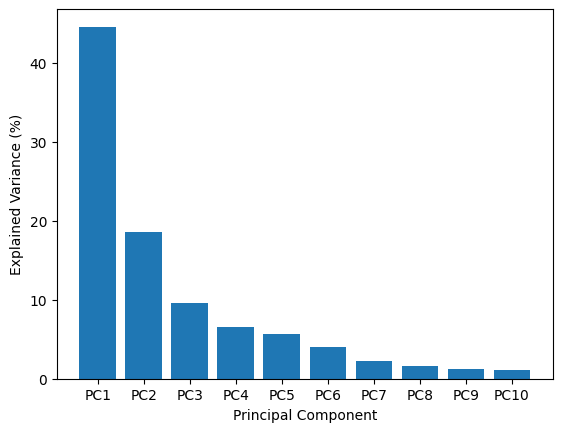

In [9]:
pca_full = PCA()
pca_full.fit(X_train_scaled)

explained_variance = pca_full.explained_variance_ratio_

plt.bar(range(1, 11), explained_variance[:10] * 100,
        tick_label=[f'PC{i}' for i in range(1, 11)])
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.show()

In [14]:
n_components = 4
pca = PCA(n_components=n_components)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

model_after = LogisticRegression(max_iter=10000)
model_after.fit(X_train_pca, y_train)

y_pred_train_after = model_after.predict(X_train_pca)
y_pred_test_after = model_after.predict(X_test_pca)

print('Number of Components:', n_components)
print('Logistic Regression - With PCA')
print('\nTraining Statistics')
print('Confusion Matrix:')
print(confusion_matrix(y_train, y_pred_train_after))
print('Accuracy:', accuracy_score(y_train, y_pred_train_after))
print('Precision:', precision_score(y_train, y_pred_train_after))
print('Recall:', recall_score(y_train, y_pred_train_after))
print('F1-Score:', f1_score(y_train, y_pred_train_after))

print('\nTesting Statistics')
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred_test_after))
print('Accuracy:', accuracy_score(y_test, y_pred_test_after))
print('Precision:', precision_score(y_test, y_pred_test_after))
print('Recall:', recall_score(y_test, y_pred_test_after))
print('F1-Score:', f1_score(y_test, y_pred_test_after))

Number of Components: 4
Logistic Regression - With PCA

Training Statistics
Confusion Matrix:
[[279   6]
 [ 11 159]]
Accuracy: 0.9626373626373627
Precision: 0.9636363636363636
Recall: 0.9352941176470588
F1-Score: 0.9492537313432836

Testing Statistics
Confusion Matrix:
[[72  0]
 [ 3 39]]
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1-Score: 0.9629629629629629
